# Álgebra Linear, Vetores e Geometria Analítica — Entrega 2
## PCA, mínimos quadrados e redução de dimensionalidade no Agente de Monitoramento

Na Entrega 1 representamos cada aluno como um **vetor** e a turma como uma **matriz**. Aqui usamos essa mesma estrutura sobre **as features do modelo de risco da E1** para:

1. montar a matriz de dados padronizada **X** (alunos × atributos);
2. implementar a **PCA** com autovalores e autovetores da matriz de covariância (NumPy) e conferir com o scikit-learn;
3. ler a **variância explicada** (scree plot), as **cargas** de cada componente e a **projeção 2D** colorida por evasão e por faixa de risco;
4. resolver uma regressão pelas **equações normais** (mínimos quadrados) e comparar com a regressão logística;
5. medir o **efeito da redução de dimensionalidade** no desempenho do modelo.

Dados reais lidos de `data/` (fora do Git). Só aparecem agregados e gráficos de pontos sem identificação.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ML = Path.cwd() if (Path.cwd() / "treinar.py").exists() else Path.cwd() / "ml"
sys.path.insert(0, str(ML))
import warnings; warnings.filterwarnings("ignore")
from risco import dados, graficos as g
from risco.modelo import RiskModel
%matplotlib inline
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)

df, rel = dados.carregar_limpo()           # mesma limpeza da E1
treino, teste = dados.dividir(df)          # mesmo split (75/25, semente 42)
NUM, CAT = list(dados.NUMERICAS_E1), list(dados.CATEGORICAS_E1)
print(f"{rel.linhas_finais} alunos · {len(NUM)} atributos numéricos/binários · {len(CAT)} categóricos")

12835 alunos · 17 atributos numéricos/binários · 5 categóricos


## 1. Matriz de dados X e padronização

Cada aluno vira um vetor-linha **xᵢ ∈ ℝᵖ**. Os atributos categóricos viram colunas 0/1 (*one-hot*, descartando uma categoria de referência para não criar colunas linearmente dependentes). Depois, cada coluna é **padronizada**:

$$z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}$$

Sem isso, `valor_total_periodo` (até R$ 410 mil) dominaria qualquer distância ou variância só por causa da unidade de medida.

In [2]:
def matriz(d, colunas=None):
    M = pd.concat([d[NUM].astype(float), pd.get_dummies(d[CAT].astype(str), drop_first=True, dtype=float)], axis=1)
    return M if colunas is None else M.reindex(columns=colunas, fill_value=0.0)

Mtr = matriz(treino); cols = list(Mtr.columns); Mte = matriz(teste, cols)
mu, sigma = Mtr.mean().to_numpy(), Mtr.std(ddof=0).to_numpy()
X  = (Mtr.to_numpy() - mu) / sigma           # padronização com estatísticas do TREINO
Xt = (Mte.to_numpy() - mu) / sigma           # o teste usa as mesmas μ e σ (sem vazamento)
y, yt = treino.evadiu.to_numpy(), teste.evadiu.to_numpy()
n, p = X.shape
print(f"X: {n} alunos × {p} colunas | médias ≈ {np.abs(X.mean(0)).max():.1e} | desvios = {X.std(0).min():.3f}…{X.std(0).max():.3f}")

X: 9626 alunos × 33 colunas | médias ≈ 1.5e-16 | desvios = 1.000…1.000


**Para o agente:** depois da padronização, "estar 2 desvios acima da média" significa a mesma coisa em notas, atraso ou valor. É essa escala comum que permite comparar alunos por distância e somar contribuições de atributos diferentes.

## 2. PCA via autovalores e autovetores da covariância

Com X centrada, a matriz de covariância é

$$\Sigma = \frac{1}{n-1} X^\top X \in \mathbb{R}^{p \times p}$$

Σ é simétrica e semidefinida positiva, então tem autovalores reais λ₁ ≥ … ≥ λₚ ≥ 0 e autovetores ortonormais **v₁, …, vₚ**. Cada autovetor é uma **direção** no espaço dos atributos (um *componente principal*), e o autovalor correspondente é a **variância dos dados projetados** nessa direção:

$$\Sigma v_k = \lambda_k v_k, \qquad \operatorname{Var}(X v_k) = \lambda_k$$

In [3]:
Sigma = (X.T @ X) / (n - 1)
autovalores, autovetores = np.linalg.eigh(Sigma)          # eigh: para matrizes simétricas
ordem = np.argsort(autovalores)[::-1]
lam, V = autovalores[ordem], autovetores[:, ordem]
lam = np.clip(lam, 0, None)                               # ruído numérico em λ≈0

print("Σ simétrica:", np.allclose(Sigma, Sigma.T))
print("V ortonormal (VᵀV = I):", np.allclose(V.T @ V, np.eye(p), atol=1e-8))
print("Σ v₁ = λ₁ v₁:", np.allclose(Sigma @ V[:, 0], lam[0] * V[:, 0]))
print("Soma dos autovalores = traço(Σ) = p:", round(lam.sum(), 4), "=", round(np.trace(Sigma), 4))
print("Var(X v₁) =", round((X @ V[:, 0]).var(ddof=1), 4), "≈ λ₁ =", round(lam[0], 4))

Σ simétrica: True
V ortonormal (VᵀV = I): True
Σ v₁ = λ₁ v₁: True
Soma dos autovalores = traço(Σ) = p: 33.0034 = 33.0034
Var(X v₁) = 8.2203 ≈ λ₁ = 8.2203


**Conferência com o scikit-learn.** A `PCA` do scikit-learn usa SVD (decomposição em valores singulares), um caminho numérico diferente. Os autovalores devem coincidir e os autovetores podem diferir só no **sinal** (v e −v são a mesma direção).

In [4]:
from sklearn.decomposition import PCA
pca = PCA().fit(X)
sinais = np.sign(np.sum(pca.components_ * V.T, axis=1))
print("autovalores iguais:", np.allclose(pca.explained_variance_, lam, atol=1e-8))
print("autovetores iguais (a menos do sinal):", np.allclose(pca.components_ * sinais[:, None], V.T, atol=1e-6))
print("maior diferença |λ_numpy − λ_sklearn|:", f"{np.abs(pca.explained_variance_ - lam).max():.2e}")

autovalores iguais: True
autovetores iguais (a menos do sinal): True
maior diferença |λ_numpy − λ_sklearn|: 0.00e+00


**Para o agente:** as duas implementações produzem a mesma base ortonormal. A versão NumPy, com poucas linhas de álgebra, é suficiente e auditável; nada de "caixa-preta" para reduzir os dados.

## 3. Variância explicada e scree plot

A fração de variância explicada pelo componente k é λₖ / Σⱼ λⱼ.

PC1 explica 24.9%, PC2 8.8%, PC1+PC2 33.7%
Componentes para 80% / 90% / 95% da variância: 15 / 19 / 22 (de 33)
Critério de Kaiser (λ > 1): 11 componentes


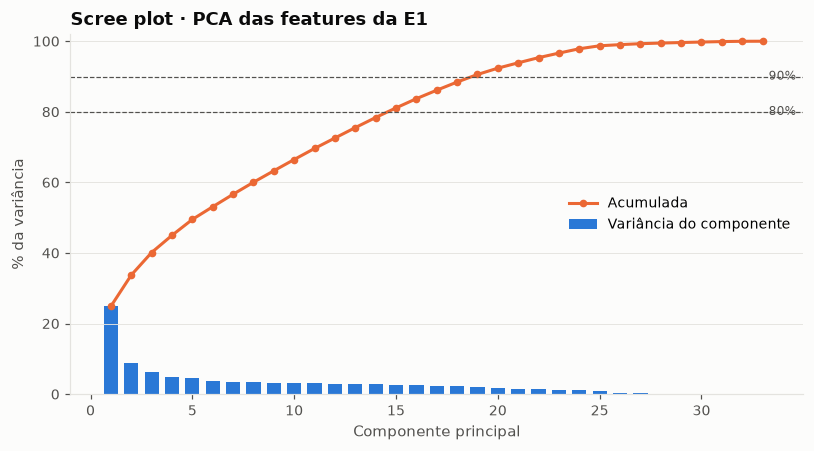

In [5]:
ve = lam / lam.sum(); vac = np.cumsum(ve)
k80, k90, k95 = [int(np.argmax(vac >= t) + 1) for t in (0.80, 0.90, 0.95)]
print(f"PC1 explica {ve[0]:.1%}, PC2 {ve[1]:.1%}, PC1+PC2 {vac[1]:.1%}")
print(f"Componentes para 80% / 90% / 95% da variância: {k80} / {k90} / {k95} (de {p})")
print("Critério de Kaiser (λ > 1):", int((lam > 1).sum()), "componentes")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
k = np.arange(1, p + 1)
ax.bar(k, ve * 100, color=g.SERIE[0], width=0.7, label="Variância do componente")
ax.plot(k, vac * 100, color=g.SERIE[1], marker="o", ms=4, label="Acumulada")
for t in (80, 90):
    ax.axhline(t, color=g.TEXTO_2, lw=0.8, ls="--")
    ax.text(p + 0.3, t, f"{t}%", va="center", fontsize=8, color=g.TEXTO_2)
ax.set(xlabel="Componente principal", ylabel="% da variância", title="Scree plot · PCA das features da E1", ylim=(0, 102))
ax.legend(loc="center right"); ax.grid(axis="x", visible=False)
g.salvar(fig, "algebra_scree_plot.png"); plt.show()

**Leitura e o que significa para o agente:** o PC1 sozinho explica **~25%** da variância, mas depois dele a curva achata: PC1+PC2 chegam a ~34%, e são precisos **15 de 33 componentes para 80%** e 19 para 90% (Kaiser indica 11). Há um eixo dominante e, fora dele, informação espalhada em muitas direções pouco correlacionadas. Não dá para resumir o aluno em 2 ou 3 números sem perder informação; a seção 7 mede quanto isso custa na previsão.

## 4. Interpretação dos componentes (cargas)

A **carga** do atributo j no componente k é a coordenada j do autovetor vₖ: quanto aquele atributo "puxa" a direção. Cargas de mesmo sinal andam juntas.


PC1 (24.9% da variância):
media_assiduidade               0.308
Turno_Manhã                     0.299
media_notas                     0.297
total_semestres                 0.296
Grau Acadêmico_Pós-Graduação   -0.296
Turno_Noite                    -0.290

PC2 (8.8% da variância):
Estado Civil_Nao informado   -0.359
Estado Civil_Solteiro         0.338
total_parcelas                0.310
Idade                         0.276
valor_total_periodo           0.268
tempo_de_curso                0.248

PC3 (6.4% da variância):
Estado Civil_Nao informado    0.388
Estado Civil_Solteiro        -0.379
tem_bolsa                     0.302
total_parcelas                0.271
total_contatos                0.269
valor_total_periodo           0.260


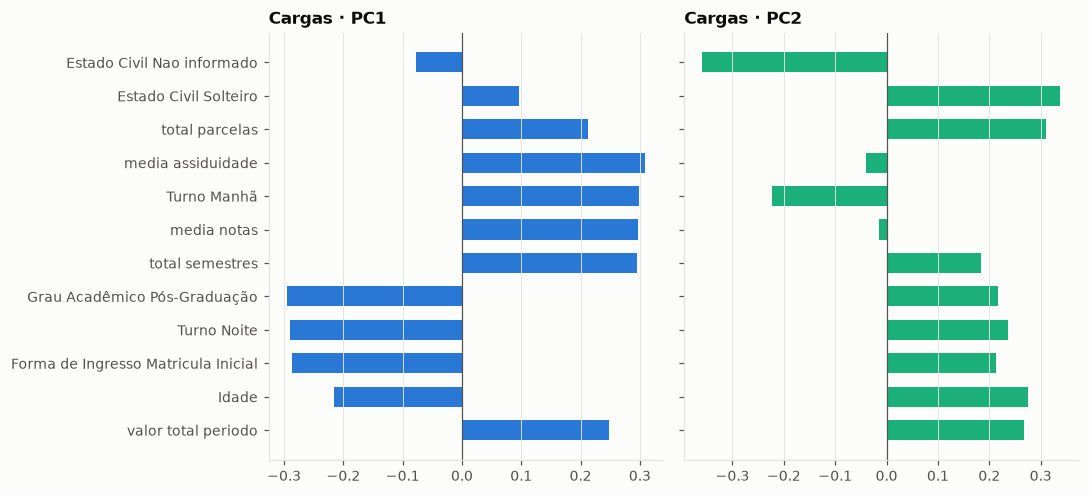

In [6]:
cargas = pd.DataFrame(V[:, :4], index=cols, columns=["PC1", "PC2", "PC3", "PC4"])
for pc in ["PC1", "PC2", "PC3"]:
    top = cargas[pc].abs().sort_values(ascending=False).head(6).index
    print(f"\n{pc} ({ve[int(pc[2]) - 1]:.1%} da variância):")
    print(cargas.loc[top, pc].round(3).to_string())

top = cargas[["PC1", "PC2"]].abs().max(axis=1).sort_values(ascending=False).head(12).index
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
for ax, pc, cor in zip(axes, ["PC1", "PC2"], [g.SERIE[0], g.SERIE[2]]):
    v = cargas.loc[top[::-1], pc]
    ax.barh([c.replace("_", " ") for c in v.index], v.values, color=cor, height=0.6)
    ax.axvline(0, color=g.TEXTO_2, lw=0.8); ax.set_title(f"Cargas · {pc}", fontsize=11); ax.grid(axis="y", visible=False)
g.salvar(fig, "algebra_cargas_pc1_pc2.png"); plt.show()

**Leitura:**
- **PC1 (25%) — "graduação diurna com histórico × pós-graduação noturna sem histórico"**: frequência, notas, semestres cursados e turno da manhã de um lado; pós-graduação e turno da noite do outro. É o eixo que separa os dois públicos da instituição.
- **PC2 (9%) — "tamanho do contrato"**: total de parcelas, valor do período, tempo de curso e idade andam juntos, misturados com o **preenchimento do estado civil** ("Não informado" × "Solteiro").
- **PC3 (6%)** repete o estado civil e soma bolsa, parcelas e contatos.

**Para o agente:**
1. O **estado civil** aparece em PC2 e PC3 não como informação pessoal, mas como **padrão de cadastro** (quem tem o campo "Não informado" é, em geral, aluno de pós). É mais um argumento para tê-lo retirado do modelo: ele só repete o grau acadêmico por um caminho sensível.
2. **Parcelas em aberto e atraso**, que o atendente vê como fatores financeiros, **não estão entre as maiores cargas** dos 3 primeiros componentes: têm pouca variância (a maioria dos alunos está em dia), mesmo sendo relevantes para o risco. A PCA ordena direções por *variância*, não por *relevância para a evasão*; a seção 7 mostra a consequência disso.

## 5. Projeção 2D

Projetar é multiplicar pela matriz dos dois primeiros autovetores: **Z = X · [v₁ v₂]**. Cada aluno vira um ponto no plano.

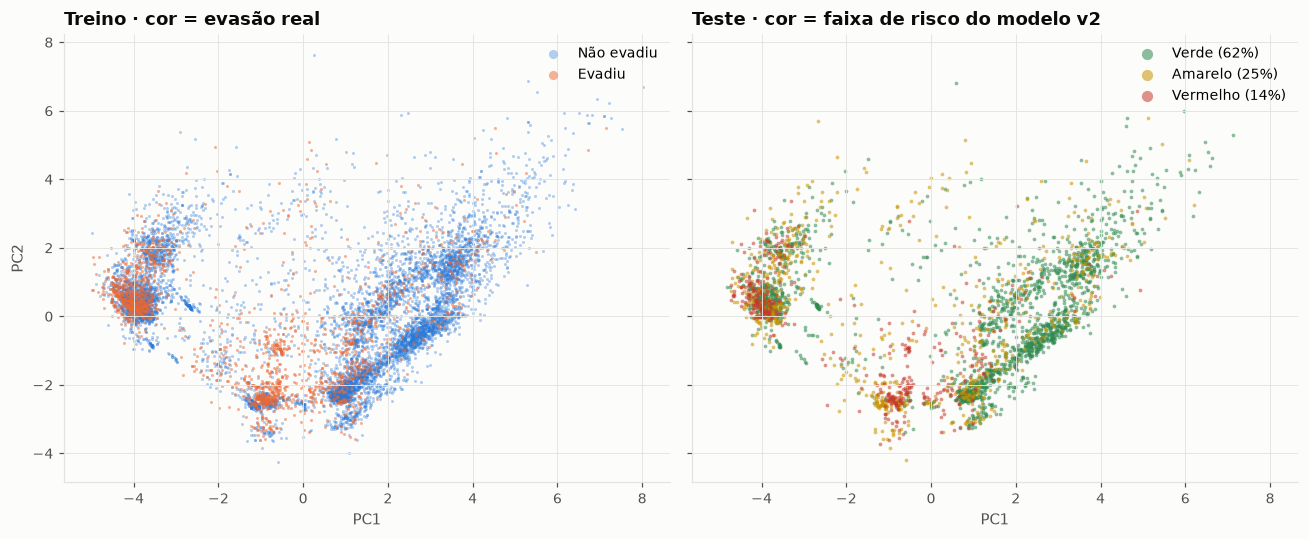

Centroide de cada faixa no plano PC1×PC2 (teste):


,PC1,PC2
verde,0.698,0.130
amarelo,-0.783,0.082
vermelho,-1.752,-0.552


In [7]:
Z, Zt = X @ V[:, :2], Xt @ V[:, :2]
modelo = RiskModel.carregar(ML / "artifacts" / "risco_v2.joblib")
p_te = modelo.probabilidades(teste)
lim = modelo.a["limiares_recomendados"]
faixa = np.where(p_te >= lim["vermelho"], "vermelho", np.where(p_te >= lim["amarelo"], "amarelo", "verde"))

rng = np.random.default_rng(42)
idx = rng.permutation(len(Z))
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for val, cor, rot in ((0, g.SERIE[0], "Não evadiu"), (1, g.SERIE[1], "Evadiu")):
    m = y[idx] == val
    axes[0].scatter(Z[idx][m, 0], Z[idx][m, 1], s=4, alpha=0.35 if val == 0 else 0.5, color=cor, label=rot, linewidths=0)
axes[0].set(title="Treino · cor = evasão real", xlabel="PC1", ylabel="PC2")
for c in ("verde", "amarelo", "vermelho"):
    m = faixa == c
    axes[1].scatter(Zt[m, 0], Zt[m, 1], s=6, alpha=0.55, color=g.RISCO[c], label=f"{c.capitalize()} ({m.mean():.0%})", linewidths=0)
axes[1].set(title="Teste · cor = faixa de risco do modelo v2", xlabel="PC1")
for ax in axes:
    ax.legend(loc="upper right", markerscale=3)
g.salvar(fig, "algebra_projecao_2d.png"); plt.show()

cent = pd.DataFrame(Zt, columns=["PC1", "PC2"]).groupby(faixa).mean().reindex(["verde", "amarelo", "vermelho"])
print("Centroide de cada faixa no plano PC1×PC2 (teste):"); display(cent)

**Leitura:** a evasão se concentra no lado de **PC1 negativo** (pós-graduação/noite, pouco histórico lançado), e as faixas do modelo seguem a mesma geometria: os centroides no teste ficam em PC1 ≈ +0,7 (Verde), −0,8 (Amarelo) e −1,8 (Vermelho), em ordem. Mas há **muita sobreposição**: no plano, alunos que evadem e que ficam se misturam.

**Para o agente:** 2 dimensões bastam para *visualizar* a população (um mapa para o dashboard do administrador), não para *decidir*. Quem decide é o modelo com todas as dimensões.

## 6. Mínimos quadrados pelas equações normais

Queremos β que minimize ‖y − Aβ‖², com A = [**1** | X] (coluna de uns para o intercepto). Derivando e igualando a zero:

$$A^\top A\, \beta = A^\top y \quad\Longrightarrow\quad \hat\beta = (A^\top A)^{-1} A^\top y$$

Geometricamente, Aβ̂ é a **projeção ortogonal** de y no espaço gerado pelas colunas de A: o resíduo y − Aβ̂ é ortogonal a todas as colunas. Com y ∈ {0, 1}, isso é o *modelo de probabilidade linear*.

In [8]:
A  = np.column_stack([np.ones(n), X]); At = np.column_stack([np.ones(len(Xt)), Xt])
AtA, Aty = A.T @ A, A.T @ y
beta = np.linalg.solve(AtA, Aty)                       # resolve o sistema (mais estável que inverter)
residuo = y - A @ beta

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import roc_auc_score
lr_lin = LinearRegression().fit(X, y)
beta_lstsq = np.linalg.lstsq(A, y, rcond=None)[0]

print(f"número de condição de AᵀA: {np.linalg.cond(AtA):.1f}")
print("β (equações normais) = β (lstsq/SVD):", np.allclose(beta, beta_lstsq, atol=1e-8))
print("β = scikit-learn LinearRegression:", np.allclose(beta, np.r_[lr_lin.intercept_, lr_lin.coef_], atol=1e-8))
print(f"ortogonalidade: max |Aᵀ(y − Aβ)| = {np.abs(A.T @ residuo).max():.1e}")
print(f"R² no treino: {1 - residuo @ residuo / ((y - y.mean()) @ (y - y.mean())):.3f}")

número de condição de AᵀA: 1397.1
β (equações normais) = β (lstsq/SVD): True
β = scikit-learn LinearRegression: True
ortogonalidade: max |Aᵀ(y − Aβ)| = 8.7e-12
R² no treino: 0.216


**Comparação com a regressão logística.** A logística modela o *log-odds* (não a probabilidade diretamente) e não tem solução fechada: é resolvida por otimização iterativa. Comparamos previsão (AUC no teste) e a direção dos coeficientes.

,AUC teste
Mínimos quadrados (eq. normais),0.803
Regressão logística,0.821
Modelo v2 (XGBoost monotônico),0.913


Previsões de MQ fora de [0, 1]: 13.6% dos alunos do teste
Mesmo sinal em 91% dos coeficientes | correlação de Spearman 0.89


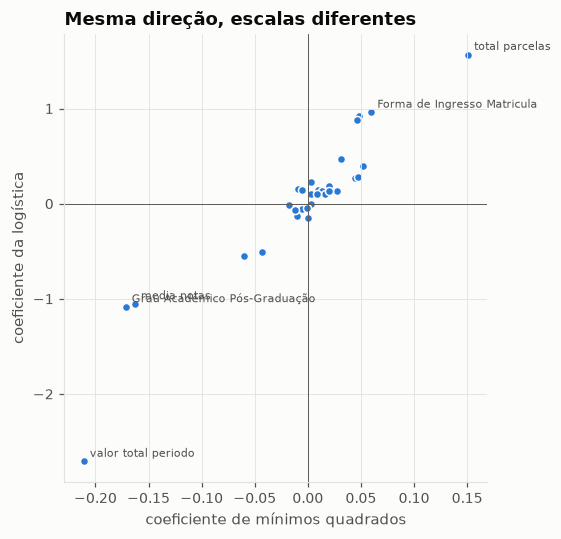

In [9]:
y_lin = At @ beta
logit = LogisticRegression(max_iter=3000, C=1.0).fit(X, y)
p_log = logit.predict_proba(Xt)[:, 1]
fora = ((y_lin < 0) | (y_lin > 1)).mean()
comp = pd.DataFrame({"AUC teste": [roc_auc_score(yt, y_lin), roc_auc_score(yt, p_log), roc_auc_score(yt, p_te)]},
                    index=["Mínimos quadrados (eq. normais)", "Regressão logística", "Modelo v2 (XGBoost monotônico)"])
display(comp)
coef = pd.DataFrame({"MQ (β)": beta[1:], "Logística (w)": logit.coef_[0]}, index=cols)
print(f"Previsões de MQ fora de [0, 1]: {fora:.1%} dos alunos do teste")
print(f"Mesmo sinal em {np.mean(np.sign(coef['MQ (β)']) == np.sign(coef['Logística (w)'])):.0%} dos coeficientes | correlação de Spearman {coef.corr(method='spearman').iloc[0, 1]:.2f}")

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(coef["MQ (β)"], coef["Logística (w)"], s=28, color=g.SERIE[0], edgecolor=g.SUPERFICIE, linewidth=1)
for nome in coef["Logística (w)"].abs().sort_values().index[-5:]:
    ax.annotate(nome.replace("_", " ")[:28], (coef.loc[nome, "MQ (β)"], coef.loc[nome, "Logística (w)"]), fontsize=7.5, color=g.TEXTO_2,
                xytext=(4, 3), textcoords="offset points")
ax.axhline(0, color=g.TEXTO_2, lw=0.6); ax.axvline(0, color=g.TEXTO_2, lw=0.6)
ax.set(xlabel="coeficiente de mínimos quadrados", ylabel="coeficiente da logística", title="Mesma direção, escalas diferentes")
g.salvar(fig, "algebra_mq_vs_logistica.png"); plt.show()

**Leitura:** as equações normais, o `lstsq` (SVD) e o scikit-learn dão o mesmo β, e o resíduo é ortogonal às colunas de A (≈10⁻¹¹), como a teoria prevê. O número de condição de AᵀA (~1.400) é moderado: há colinearidade entre colunas (parcelas, valor, tempo de curso), mas nada que torne o sistema instável. A AUC dos mínimos quadrados (**0,80**) fica só **0,02 abaixo da logística (0,82)**, e os coeficientes têm o mesmo sinal em 91% dos atributos (Spearman 0,89): para *ordenar* alunos por risco, a reta captura quase tudo que um modelo linear consegue.

**Para o agente:** o problema dos mínimos quadrados é o **score**, não o ranking: **13,6% das previsões saem de [0, 1]**, e uma "probabilidade" de −0,1 ou 1,2 não pode ser mostrada ao atendente. Por isso o score exibido vem de um modelo probabilístico calibrado. O salto de 0,82 para 0,91 vem de abandonar a linearidade (árvores), não de trocar reta por logística.

## 7. Efeito da redução de dimensionalidade no desempenho

Treinamos a mesma regressão logística usando só os **k primeiros componentes** (Z = X·Vₖ) e medimos a AUC no teste. A PCA é ajustada só no treino.

,variância explicada,AUC logística,AUC XGBoost
k,,,
1,0.249,0.669,0.731
2,0.337,0.655,0.756
3,0.401,0.698,0.770
5,0.495,0.690,0.794
8,0.600,0.738,0.825
10,0.665,0.748,0.832
15,0.811,0.748,0.831
20,0.924,0.752,0.845
25,0.987,0.767,0.849


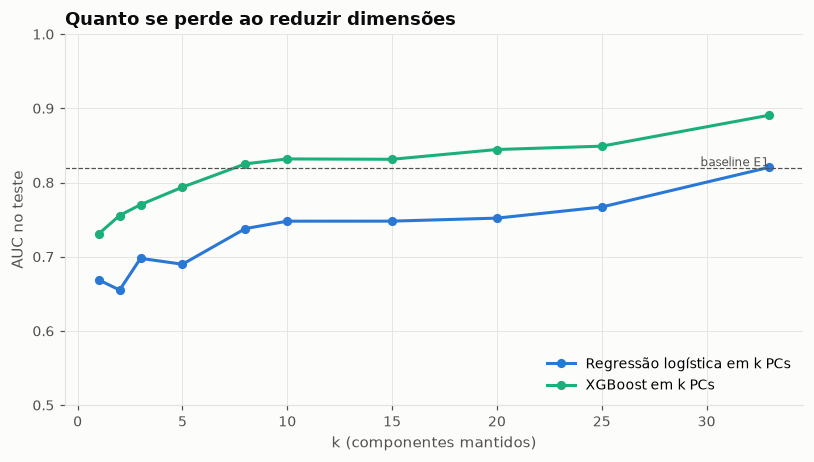

In [10]:
from xgboost import XGBClassifier
ks = [1, 2, 3, 5, 8, 10, 15, 20, 25, p]
res = []
for kk in ks:
    Zk, Ztk = X @ V[:, :kk], Xt @ V[:, :kk]
    a_log = roc_auc_score(yt, LogisticRegression(max_iter=3000).fit(Zk, y).predict_proba(Ztk)[:, 1])
    a_xgb = roc_auc_score(yt, XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, n_jobs=-1, random_state=42).fit(Zk, y).predict_proba(Ztk)[:, 1])
    res.append({"k": kk, "variância explicada": vac[kk - 1], "AUC logística": a_log, "AUC XGBoost": a_xgb})
res = pd.DataFrame(res).set_index("k"); display(res)

fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(res.index, res["AUC logística"], marker="o", ms=5, color=g.SERIE[0], label="Regressão logística em k PCs")
ax.plot(res.index, res["AUC XGBoost"], marker="o", ms=5, color=g.SERIE[2], label="XGBoost em k PCs")
ax.axhline(0.82, color=g.TEXTO_2, lw=0.8, ls="--"); ax.text(p, 0.822, "baseline E1", ha="right", fontsize=8, color=g.TEXTO_2)
ax.set(xlabel="k (componentes mantidos)", ylabel="AUC no teste", title="Quanto se perde ao reduzir dimensões", ylim=(0.5, 1))
ax.legend(loc="lower right")
g.salvar(fig, "algebra_reducao_dimensionalidade.png"); plt.show()

**Leitura:** a redução custa caro. Com 15 componentes (81% da variância) a logística cai de **0,82 para 0,75**; mesmo com 25 componentes (**98,7% da variância**) fica em 0,77. Os 8 últimos componentes somam só 1,3% da variância, mas carregam boa parte do sinal: **variância não é relevância**. A PCA escolhe direções pelo quanto os atributos variam, não pela relação com a evasão (é o caso de parcelas em aberto e atraso, seção 4). Para o XGBoost, mesmo com todos os 33 componentes a AUC (0,89) fica abaixo da obtida nos atributos originais (~0,93): árvores cortam um atributo por vez, e a rotação mistura atributos e destrói cortes simples como "nota < 60".

**Para o agente:**
- **Não usamos PCA no modelo de produção:** a economia é irrelevante (33 colunas não pesam em nada), a perda de AUC é grande, e um componente ("0,3·frequência − 0,3·pós-graduação + …") não vira um fator que o atendente entenda.
- **A PCA é útil para** visualizar a população (mapa 2D no dashboard), detectar alunos atípicos (distância grande ao centro) e checar se as dimensões dos fatores fazem sentido (seção 4).

In [11]:
resumo = {
    "p_colunas": int(p), "n_treino": int(n),
    "variancia_pc1": round(float(ve[0]), 4), "variancia_pc1_pc2": round(float(vac[1]), 4),
    "componentes_80_90_95": [k80, k90, k95], "kaiser": int((lam > 1).sum()),
    "numpy_igual_sklearn": bool(np.allclose(pca.explained_variance_, lam, atol=1e-8)),
    "mq_auc_teste": round(float(comp.iloc[0, 0]), 4), "logistica_auc_teste": round(float(comp.iloc[1, 0]), 4),
    "mq_previsoes_fora_0_1": round(float(fora), 4),
    "auc_por_k": {int(k_): {"logistica": round(float(r["AUC logística"]), 4), "xgboost": round(float(r["AUC XGBoost"]), 4),
                            "variancia": round(float(r["variância explicada"]), 4)} for k_, r in res.iterrows()},
}
(ML / "artifacts" / "algebra_metrics.json").write_text(json.dumps(resumo, ensure_ascii=False, indent=2))
print(json.dumps({k: v for k, v in resumo.items() if k != "auc_por_k"}, ensure_ascii=False))

{"p_colunas": 33, "n_treino": 9626, "variancia_pc1": 0.2491, "variancia_pc1_pc2": 0.3374, "componentes_80_90_95": [15, 19, 22], "kaiser": 11, "numpy_igual_sklearn": true, "mq_auc_teste": 0.8033, "logistica_auc_teste": 0.8206, "mq_previsoes_fora_0_1": 0.1362}


## Conclusão

| Operação | O que fizemos | O que significa para o agente |
|---|---|---|
| Padronização | z = (x − μ)/σ com estatísticas do treino | Atributos em escala comum; base para distâncias e contribuições |
| Autovalores/autovetores de Σ | PCA em NumPy, idêntica ao scikit-learn | O eixo principal separa graduação com histórico de pós sem histórico; estado civil aparece como padrão de cadastro, não como informação útil |
| Projeção Z = XV₂ | Mapa 2D por evasão e por faixa | Bom para visualizar e achar atípicos; insuficiente para decidir |
| Equações normais | β = (AᵀA)⁻¹Aᵀy, resíduo ortogonal | Ordena quase tão bem quanto a logística, mas gera "probabilidades" fora de [0,1] |
| Redução de dimensionalidade | AUC × k componentes | Variância ≠ relevância: perde AUC e explicabilidade; não entra no modelo de produção |